# W15. Etyka i audyt sprawiedliwości modeli

**Wersja źródła:** 1.3.4 · **Data:** 2026-11-04

In [1]:
import numpy as np
import pandas as pd
from scipy.special import expit
rng = np.random.default_rng(42)
grupa = np.array(["A"]*360 + ["B"]*240)
cecha = rng.normal(size=len(grupa))
y = rng.binomial(1, expit(1.1*cecha-.15))
wynik = expit(1.2*cecha+rng.normal(0,.7,len(grupa))
              -.7*(grupa=="B"))
pred = (wynik >= .5).astype(int)


In [2]:
from sklearn.metrics import confusion_matrix,brier_score_loss
raport=[]
for g in ["A","B"]:
    maska=grupa==g
    tn,fp,fn,tp=confusion_matrix(y[maska],pred[maska],labels=[0,1]).ravel()
    raport.append({"grupa":g,"n":int(maska.sum()),
        "n_plus":int(tp+fn),"n_minus":int(tn+fp),
        "czulosc":tp/(tp+fn),"swoistosc":tn/(tn+fp),
        "ppv":tp/(tp+fp),"odsetek_decyzji_plus":(tp+fp)/maska.sum(),
        "brier":brier_score_loss(y[maska],wynik[maska]),
        "tp":int(tp),"fn":int(fn)})
df=pd.DataFrame(raport)
print(df.round(3).to_string(index=False))


grupa   n  n_plus  n_minus  czulosc  swoistosc   ppv  odsetek_decyzji_plus  brier  tp  fn
    A 360     166      194    0.717      0.660 0.643                 0.514  0.192 119  47
    B 240     107      133    0.402      0.857 0.694                 0.258  0.216  43  64


A liczebności koszyków: [72, 72, 72, 72, 72]
B liczebności koszyków: [48, 48, 48, 48, 48]


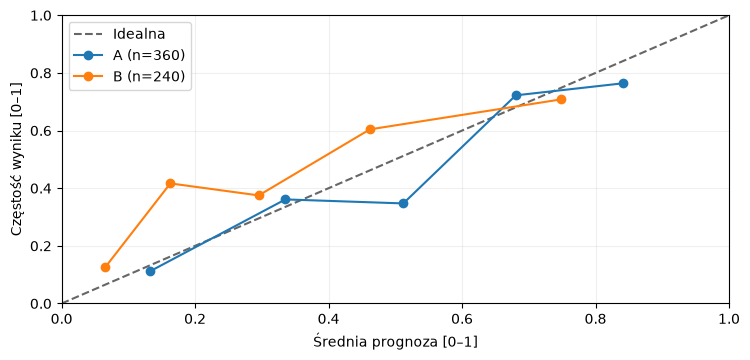

In [3]:
import matplotlib.pyplot as plt
kalibracja = {}
fig, ax = plt.subplots(figsize=(7.6, 3.7))
ax.plot([0, 1], [0, 1], "--", color="0.4", label="Idealna")
for g in ("A", "B"):
    ix = np.flatnonzero(grupa == g)
    koszyki = np.array_split(ix[np.argsort(wynik[ix])], 5)
    punkty = np.array([(wynik[b].mean(), y[b].mean(), len(b))
                       for b in koszyki])
    kalibracja[g] = punkty
    ax.plot(punkty[:, 0], punkty[:, 1], marker="o",
            label=f"{g} (n={len(ix)})")
    print(g, "liczebności koszyków:", punkty[:, 2].astype(int).tolist())
ax.set(xlabel="Średnia prognoza [0–1]",
       ylabel="Częstość wyniku [0–1]", xlim=(0, 1), ylim=(0, 1))
ax.legend(); ax.grid(alpha=.2)
plt.tight_layout(); plt.show()


In [4]:
# Bootstrap różnicy czułości między grupami
rng_ci = np.random.default_rng(2026)
roznice = []
for _ in range(1000):
    sens = []
    for g in ["A","B"]:
        ix = np.flatnonzero(grupa==g)
        bs = rng_ci.choice(ix,size=len(ix),replace=True)
        mask = y[bs] == 1
        sens.append(np.mean(pred[bs][mask]) if np.any(mask) else np.nan)
    roznice.append(sens[0]-sens[1])
print("Różnica A−B, 95% bootstrap CI:",
      np.round(np.nanpercentile(roznice,[2.5,97.5]),3))


Różnica A−B, 95% bootstrap CI: [0.199 0.437]
